# Calibração do modelo de Rosenzweig-MacArthur

O objetivo deste notebook é estudar a **calibração dos parâmetros do modelo de Rosenzweig-MacArthur** a partir de dados populacionais de presas e predadores.

O modelo de Rosenzweig-MacArthur é uma extensão do modelo clássico de Lotka-Volterra, incorporando o crescimento logístico das presas e uma resposta funcional de Holling tipo II, que considera a saturação da taxa de predação.

Inicialmente, serão gerados **dados sintéticos** a partir de valores conhecidos dos parâmetros do modelo. Para isso, o sistema de equações diferenciais ordinárias (EDOs) será resolvido numericamente, considerando condições iniciais previamente definidas.

Posteriormente, esses dados serão utilizados na resolução do **problema inverso de identificação de parâmetros**, permitindo avaliar e comparar diferentes técnicas de calibração, incluindo métodos clássicos de otimização, algoritmos genéticos e abordagens baseadas em redes neurais.

## Modelo de Rosenzweig-MacArthur

O modelo de **Rosenzweig-MacArthur** é uma extensão do modelo clássico de Lotka-Volterra, incorporando o crescimento logístico das presas e uma resposta funcional de Holling tipo II, que representa a saturação da taxa de predação.

O sistema de equações diferenciais ordinárias é dado por:

$$
\frac{dN}{dt} = rN\left(1-\frac{N}{K}\right)-\frac{aNP}{1+ahN}
$$

$$
\frac{dP}{dt} = e\frac{aNP}{1+ahN}-mP
$$

em que:

- $N(t)$ representa a população de presas;
- $P(t)$ representa a população de predadores;
- $r$ é a taxa intrínseca de crescimento das presas;
- $K$ é a capacidade de suporte do ambiente para as presas;
- $a$ é a taxa de ataque dos predadores;
- $h$ é o tempo de manipulação de cada presa;
- $e$ é a eficiência de conversão das presas consumidas em crescimento da população de predadores;
- $m$ é a taxa de mortalidade dos predadores.

O vetor de parâmetros do modelo é definido por:

$$
\boldsymbol{\theta}=(r,K,a,h,e,m).
$$

A principal diferença em relação ao modelo clássico de Lotka-Volterra está na consideração de recursos limitados para as presas e na saturação da predação, tornando a dinâmica populacional mais realista em determinadas situações ecológicas.

## Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Preparando dados

### Definição dos parâmetros

Parâmetros do modelo de Rosenzweig-MacArthur

In [3]:
r = 1.0      # Taxa de crescimento das presas
K = 100.0    # Capacidade de suporte do ambiente
a = 0.05     # Taxa de ataque dos predadores
h = 0.2      # Tempo de manipulação das presas
e = 0.5      # Eficiência de conversão
m = 0.5      # Taxa de mortalidade dos predadores

In [4]:
N0 = 10.0   # população inicial de presas
P0 = 5.0    # população inicial de predadores

### Definindo modelo e solução

In [5]:
import numpy as np
from scipy.integrate import solve_ivp

def rosenzweig_macarthur(t, y, r, K, a, h, e, m):

    N, P = y

    dNdt = r * N * (1 - N / K) - (a * N * P) / (1 + a * h * N)
    dPdt = e * (a * N * P) / (1 + a * h * N) - m * P

    return [dNdt, dPdt]


t0 = 0
tf = 30
t = np.linspace(t0, tf, 1000)

solucao = solve_ivp(
    rosenzweig_macarthur,
    [t0, tf],
    [N0, P0],
    t_eval=t,
    args=(r, K, a, h, e, m),
    method="RK45",
    rtol=1e-8,
    atol=1e-10
)

# Verifica se a integração foi concluída
if not solucao.success:
    raise RuntimeError(solucao.message)

# Solução avaliada nos 1000 instantes de tempo
N = solucao.y[0]
P = solucao.y[1]

### Amostrando dados e inserindo ruído

In [9]:
t_obs = t[::50] # 50 soluções amostradas uniformemente no tempo

sigma_N = 2.0 
sigma_P = 2.0

rng_dados = np.random.default_rng(2026)

N_obs = N[::50] + rng_dados.normal(0, sigma_N, size=t_obs.size)
P_obs = P[::50] + rng_dados.normal(0, sigma_P, size=t_obs.size)

### Observando plot dos dados da solução numérica com os parâmetros reais e os amostrados com ruídos

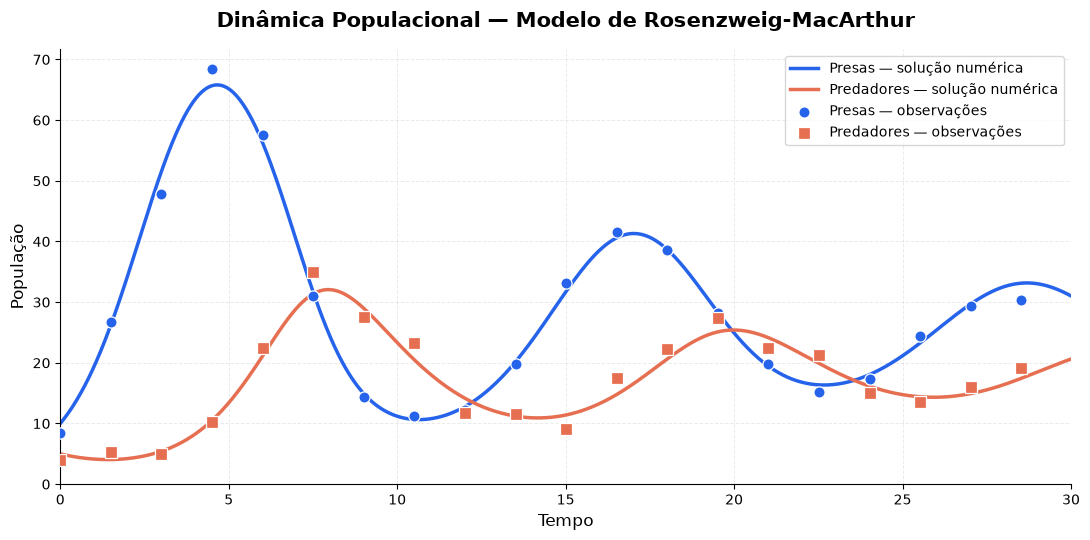

In [10]:
plt.figure(figsize=(11, 5.5))

# Cores
cor_presas = "#2563EB"
cor_predadores = "#E76F51"

# Soluções numéricas
plt.plot(
    t, N,
    color=cor_presas,
    linewidth=2.5,
    label="Presas — solução numérica"
)

plt.plot(
    t, P,
    color=cor_predadores,
    linewidth=2.5,
    label="Predadores — solução numérica"
)

# Observações amostradas
plt.scatter(
    t_obs, N_obs,
    color=cor_presas,
    edgecolors="white",
    linewidths=0.9,
    s=65,
    marker="o",
    zorder=5,
    label="Presas — observações"
)

plt.scatter(
    t_obs, P_obs,
    color=cor_predadores,
    edgecolors="white",
    linewidths=0.9,
    s=65,
    marker="s",
    zorder=5,
    label="Predadores — observações"
)

# Títulos e eixos
plt.title(
    "Dinâmica Populacional — Modelo de Rosenzweig-MacArthur",
    fontsize=15,
    fontweight="bold",
    pad=16
)

plt.xlabel("Tempo", fontsize=12)
plt.ylabel("População", fontsize=12)

# Estilo
plt.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.25
)

plt.legend(
    fontsize=10,
    loc="best",
    frameon=True,
    fancybox=True
)

plt.tick_params(axis="both", labelsize=10)

# Remover bordas superiores e direitas
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xlim(t[0], t[-1])
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()